# Holdout run

Run the selected allocator through the engine on the holdout period

Steps:
- build the holdout rebalance dates
- build holdout data dictionaries
- run on the holdout period
- check that the run covered the right period
- compare the results against the success criteria
    - Criterion 1: Sharpe above both benchmarks
    - Criterion 2: DSR ≥ 0.95

In [1]:
# Imports

import pandas as pd
import numpy as np
from vportfolio import load_data, engine, pipelines, allocators, trials, metrics, plotting
from vportfolio.params import HOLDOUT_START, LOOKBACK, HOLDOUT, HOLDOUT_LOG, TRIALS_LOG, ROOT
import matplotlib.pyplot as plt

In [2]:
# load data|

data = load_data.load_universe()
returns = data["returns"]

In [3]:
# every trading day from the first holdout decision date onwards
dates = returns.loc[HOLDOUT_START:].index

# last trading day of each month
holdout_rebal = dates.to_series().groupby([dates.year, dates.month]).max()

# drop the current, incomplete month (data ends mid-October 2026)
holdout_rebal = holdout_rebal[holdout_rebal < dates[-1].replace(day=1)]
holdout_rebal = holdout_rebal.reset_index(drop=True) # gives a plain 0, 1, 2… index, like research rebalance date. The engine reads them with .iloc

In [4]:
print(len(holdout_rebal), holdout_rebal.iloc[0].date(), holdout_rebal.iloc[-1].date())

58 2021-12-31 2026-09-30


In [5]:
# run a check on the dates before using them

# 1. sorted, no duplicates
assert holdout_rebal.is_monotonic_increasing and holdout_rebal.is_unique
# 2. every date is a real trading day in the data
assert holdout_rebal.isin(returns.index).all()
# 3. the engine needs the trading day after the last date (to close the final holding period)
assert returns.index[-1] > holdout_rebal.iloc[-1]
# 4. every decision has a full lookback window with no gaps (lookback_window asserts this itself)
for d in holdout_rebal:
    engine.lookback_window(returns, data["eligible"], d, n=LOOKBACK)

print("holdout rebalance dates ready")

holdout rebalance dates ready


## Expectations (written before the holdout run)
- Net Sharpe vs equal weight and 60/40: likely below both. In research NCO's Sharpe (0.47)
  was already below 60/40's (0.65) and about level with equal weight's (0.49). In the
  holdout, T-bill rates rose to around 4–5%, so a defensive portfolio of short Treasuries,
  the dollar and safe-haven currencies earns little above the risk-free rate
- DSR ≥ 0.95: unlikely to be met. The holdout is under 5 years (Sharpe standard error
  ≈ 0.45), so only a high Sharpe could reach 0.95, and research suggests NCO's will be modest
- Drawdown: lower than both benchmarks, especially in 2022, when 60/40 suffered as equities
  and bonds fell together. Not zero, though: NCO also holds medium-duration Treasuries and
  TIPS, which lost value as rates rose
- Overall: the pre-registered success criteria are likely not met; NCO's advantage is
  expected to remain lower risk, not a better risk-adjusted return
- Context: the holdout includes 2022, when equities and bonds fell together, followed by
  a strong equity rally (2023–2025)

In [6]:
# same data as research, with the holdout rebalance dates
data_h = {**data, "rebal_dates": holdout_rebal}
# 60/40 uses SPY and AGG from the raw file, also with the holdout dates
data_6040_h = {**load_data.load_benchmark(), "rebal_dates": holdout_rebal} # makes a copy of the dictionary and replaces only the rebalance dates

In [7]:
# the holdout run: NCO (selected) and the two pre-registered benchmarks
# results go to results/holdout/, separate from the research log
# the holdout is run once: skip if results already exist
if HOLDOUT_LOG.exists():
    print("Holdout already run on", pd.read_csv(HOLDOUT_LOG)["date"].iloc[0], "- not re-running")
else:
    row_nco = pipelines.trial_pipeline("nco", allocators.nco, "candidate", data_h,
                                       folder=HOLDOUT, trials_log=HOLDOUT_LOG)
    row_ew = pipelines.trial_pipeline("equal_weights", allocators.equal_weights, "benchmark", data_h,
                                      folder=HOLDOUT, trials_log=HOLDOUT_LOG)
    row_6040 = pipelines.trial_pipeline("sixty_forty", allocators.sixty_forty, "benchmark", data_6040_h,
                                        cap=None, lookback=1, folder=HOLDOUT, trials_log=HOLDOUT_LOG)

before looking at any result we need to make sure that no information from the research has leaked into the run

Expected: the first date in early January 2022, and the last one at the end of September 2026

In [8]:
# dates check
navs_h = trials.load_navs(["nco", "equal_weights", "sixty_forty"], folder=HOLDOUT)
print(navs_h.index[0].date(), navs_h.index[-1].date())
assert navs_h.index[0] >= pd.Timestamp("2022-01-01")   # performance starts in the holdout

2022-01-04 2026-09-30


In [9]:
# compare results
rf_daily = data["rf_daily"]
log_h = pd.read_csv(HOLDOUT_LOG).set_index("name")
cols = ["role", "ann_return", "ann_vol", "sharpe", "max_drawdown", "avg_turnover"]
log_h[cols].round(3)

,role,ann_return,ann_vol,sharpe,max_drawdown,avg_turnover
name,,,,,,
nco,candidate,0.019,0.031,-0.632,-0.071,0.112
equal_weights,benchmark,0.051,0.082,0.169,-0.150,0.040
sixty_forty,benchmark,0.070,0.112,0.307,-0.205,0.031


The allocator failed to beat cash in the holdout period, given the negative sharpe. To double check I want to take a look at the average risk free rate during the holdout period to see if it is above the NCO's annual return

In [10]:
rf_daily.loc["2022-01-04":"2026-09-30"].mean() * 252

np.float64(0.03959723296663759)

In [11]:
# criterion 1: NCO's net Sharpe above both benchmarks
sr_nco = log_h.loc["nco", "sharpe"]
sr_ew = log_h.loc["equal_weights", "sharpe"]
sr_6040 = log_h.loc["sixty_forty", "sharpe"]
print(f"NCO {sr_nco:.2f} | equal weight {sr_ew:.2f} | 60/40 {sr_6040:.2f}")
print("Criterion 1 met:", sr_nco > sr_ew and sr_nco > sr_6040)

# how confident: PSR of NCO against each benchmark's holdout Sharpe
nav_nco = navs_h["nco"].dropna()
print(f"PSR vs 0: {metrics.psr(nav_nco, rf_daily, 0):.2f} | "
      f"vs equal weight: {metrics.psr(nav_nco, rf_daily, sr_ew):.2f} | "
      f"vs 60/40: {metrics.psr(nav_nco, rf_daily, sr_6040):.2f}")

NCO -0.63 | equal weight 0.17 | 60/40 0.31
Criterion 1 met: False
PSR vs 0: 0.09 | vs equal weight: 0.04 | vs 60/40: 0.02


In [12]:
# criterion 2: DSR ≥ 0.95, with N = all 7 research trials + this holdout run (8)
research_sharpes = pd.read_csv(TRIALS_LOG)["sharpe"]
all_sharpes = pd.concat([research_sharpes, pd.Series([sr_nco])], ignore_index=True)
dsr_nco = metrics.dsr(nav_nco, rf_daily, all_sharpes)
print(f"DSR: {dsr_nco:.2f} (N = {len(all_sharpes)})")
print("Criterion 2 met:", dsr_nco >= 0.95)

DSR: 0.00 (N = 8)
Criterion 2 met: False


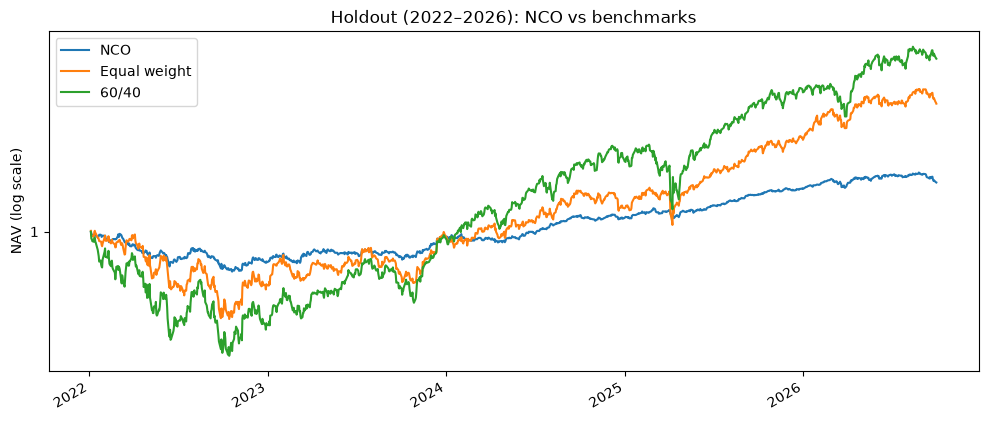

In [13]:
# NCO vs benchmarks on the holdout period

holdout_nav = trials.load_navs(["nco", "equal_weights", "sixty_forty"], folder=HOLDOUT)
holdout_nav = holdout_nav.rename(columns={"nco": "NCO",
                                          "equal_weights": "Equal weight",
                                          "sixty_forty": "60/40"})

ax = holdout_nav.plot(logy=True, figsize=(12, 5), title="Holdout (2022–2026): NCO vs benchmarks")
plotting.format_log_axis(ax)
ax.set_ylabel("NAV (log scale)")
ax.set_xlabel("")
ax.figure.savefig(ROOT / "docs" / "figures" / "holdout.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
print(log_h[cols].round(3).to_markdown())

| name          | role      |   ann_return |   ann_vol |   sharpe |   max_drawdown |   avg_turnover |
|:--------------|:----------|-------------:|----------:|---------:|---------------:|---------------:|
| nco           | candidate |        0.019 |     0.031 |   -0.632 |         -0.071 |          0.112 |
| equal_weights | benchmark |        0.051 |     0.082 |    0.169 |         -0.15  |          0.04  |
| sixty_forty   | benchmark |        0.07  |     0.112 |    0.307 |         -0.205 |          0.031 |


## Holdout (07-11-2026)
NCO, selected by the amended rule (lowest drawdown among candidates with statistically
indistinguishable Sharpes), was run once on the holdout period: 04-01-2022 to
30-09-2026, with the two pre-registered benchmarks. Results in results/holdout/

**Against the success criteria**
- Net Sharpe above both benchmarks: **not met**. NCO −0.63, equal weight 0.17, 60/40 0.31
  (PSR of NCO vs equal weight: …, vs 60/40: …)
- DSR ≥ 0.95: **not met**. DSR = … (N = 8: the 7 research trials plus this run)
- Maximum drawdown: NCO −7.1%, against −15.0% (equal weight) and −20.5% (60/40)

**Against my expectations (written before the run)**
- Expected a low Sharpe, below both benchmarks: confirmed, and lower than expected, below 0
- Expected the DSR criterion not to be met: confirmed
- Expected a lower drawdown than both benchmarks, especially in 2022: confirmed

**Findings**
- NCO earned 1.9% a year, less than T-bills over the period (≈ 3.5–4%), hence the negative
  Sharpe. Its defensive holdings (short and medium Treasuries, TIPS, the dollar, safe-haven
  currencies) lost value in 2022 as rates rose, and afterwards earned roughly the cash rate
- The risk control held: the lowest volatility and drawdown of the three
- Turnover rose to 11.2% per rebalance (8.3% in research)

**Conclusion:** the pre-registered hypothesis, that denoised cluster-based allocation beats
equal weight and 60/40 net of costs, is rejected. NCO delivered low risk, as in research,
but in a period of high interest rates low risk without excess return underperformed cash